# Pipeline 2: SIFT bag of visual words + SVM

1. Preprocess: greyscale, resize to 256, light blur
2. SIFT descriptors on a dense grid (and DoG keypoints to compare)
3. Visual vocabulary with k-means, built per fold from non-test images only
4. Bag of words histogram per image, plus a 2x2 spatial pyramid
5. SVM, same setup as the edge pipeline

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## 1 settings

In [ ]:
# folder with the Dataset folder and folds csv in it
DATA_ROOT = Path.cwd().parent
FOLDS_CSV = DATA_ROOT / "folds.csv"

# class names in id order same as the setup notebook
CLASS_NAMES = ["Crack", "Pothole", "Surface Erosion"]

# original image size and size used for sift (same 256 as the edge pipeline)
IMAGE_SIZE = 640
SIFT_SIZE = 256

# light blur before sift same as the edge pipeline (0 was tried and was slightly worse)
BLUR_SIGMA = 1.0

# dense sift: one keypoint every 8 pixels, each describing a 16 by 16 patch
GRID_STEP = 8
PATCH_SIZE = 16

# dog keypoints: keep at most this many per image
MAX_DOG_KEYPOINTS = 500

# number of visual words and how many descriptors k-means learns from
VOCAB_SIZE = 200
VOCAB_SAMPLE = 100_000

# 2 means the spatial pyramid adds 4 boxes, same grid as the edge pipeline
GRID = 2

# which example images the figures show, change to see different ones
EXAMPLE_SEED = 14

# where outputs get saved
OUTPUT_DIR = Path.cwd() / "bovw_output"
OUTPUT_DIR.mkdir(exist_ok=True)

# folds, val split and svm settings same as the edge pipeline
N_FOLDS = 5
VAL_FRACTION = 0.15
SEED = 42
C_VALUES = [0.01, 0.1, 1, 10, 100]
GAMMA_VALUES = ["scale", 0.001, 0.01, 0.1]
PCA_VARIANCE = 0.95

## 2 load data the same way as the setup notebook

In [3]:
def load_table():
    # folds csv has columns path class_name class_id fold
    table = pd.read_csv(FOLDS_CSV)
    table["full_path"] = [str(DATA_ROOT / p) for p in table["path"]]
    return table


def load_image(path):
    # same as load image in the setup notebook
    # rgb and if not 640 by 640 cut the middle square out then resize
    with Image.open(path) as im:
        img = im.convert("RGB")
    w, h = img.size
    if (w, h) != (IMAGE_SIZE, IMAGE_SIZE):
        side = min(w, h)
        left = (w - side) // 2
        top = (h - side) // 2
        img = img.crop((left, top, left + side, top + side)).resize((IMAGE_SIZE, IMAGE_SIZE))
    return np.array(img)

## 3 preprocessing

In [4]:
def prepare_image(rgb):
    # gray then smaller then a light blur, same as the edge pipeline
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (SIFT_SIZE, SIFT_SIZE), interpolation=cv2.INTER_AREA)
    if BLUR_SIGMA > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), BLUR_SIGMA)
    return gray

## 4 sift descriptors
**Dense:** a fixed grid of keypoints, so every image is described everywhere (good for texture).
**DoG:** SIFT finds its own interest points with a difference of Gaussians detector.
Each keypoint gets a 128 number SIFT descriptor.

In [5]:
sift = cv2.SIFT_create()
dog_sift = cv2.SIFT_create(nfeatures=MAX_DOG_KEYPOINTS)


def dense_keypoints():
    # a keypoint every GRID_STEP pixels, all the same size, so every image gets the same grid
    half = PATCH_SIZE // 2
    steps = range(half, SIFT_SIZE - half + 1, GRID_STEP)
    return [cv2.KeyPoint(float(x), float(y), PATCH_SIZE) for y in steps for x in steps]


DENSE_KEYPOINTS = dense_keypoints()


def sift_features(gray, keypoints="dense"):
    if keypoints == "dense":
        found, desc = sift.compute(gray, DENSE_KEYPOINTS)
    else:
        found, desc = dog_sift.detectAndCompute(gray, None)

    # dog can find no keypoints on very smooth images
    if desc is None or len(found) == 0:
        return np.zeros((0, 2)), np.zeros((0, 128), np.uint8)

    # xy is where each keypoint is and desc is its 128 number descriptor
    # sift values are whole numbers 0 to 255 so uint8 saves memory
    xy = np.array([kp.pt for kp in found])
    return xy, desc.astype(np.uint8)


def compute_all(table, keypoints="dense"):
    xys, descs = [], []
    for path in table["full_path"]:
        xy, desc = sift_features(prepare_image(load_image(path)), keypoints)
        xys.append(xy)
        descs.append(desc)
    counts = pd.Series([len(d) for d in descs]).groupby(table["class_name"]).mean().reindex(CLASS_NAMES)
    print(f"{keypoints} keypoints per image (mean per class)")
    print(counts.round(1).to_string())
    print()
    return xys, descs

## 5 visual vocabulary
k-means groups descriptors into `VOCAB_SIZE` clusters. Each cluster centre is one **visual word**.
The vocabulary is built **per fold from the non-test images only**, so the test fold never shapes the words.

In [6]:
def build_vocabulary(descs, rows, n_words):
    # take an equal share of descriptors from each image then cluster them
    rng = np.random.default_rng(SEED)
    per_image = int(np.ceil(VOCAB_SAMPLE / len(rows)))
    sample = []
    for i in rows:
        d = descs[i]
        sample.append(d[rng.choice(len(d), min(per_image, len(d)), replace=False)])
    sample = np.concatenate(sample).astype(np.float32)

    # minibatch k-means is normal k-means learning from small batches, much faster
    return MiniBatchKMeans(n_clusters=n_words, batch_size=4096, n_init=3, random_state=SEED).fit(sample)


def assign_words(vocab, descs):
    # nearest visual word for every descriptor in every image
    return [vocab.predict(d.astype(np.float32)) if len(d) else np.zeros(0, int) for d in descs]


def words_for_every_fold(table, descs, n_words=VOCAB_SIZE):
    # words[k][i] is the visual words for image i using fold k's vocabulary
    words = []
    for k in range(N_FOLDS):
        vocab = build_vocabulary(descs, table.index[table["fold"] != k], n_words)
        words.append(assign_words(vocab, descs))
    return words

## 6 bag of words histogram and spatial pyramid
Count how often each visual word appears in the image. The pyramid adds the same count for each box of
a 2x2 grid, so the histogram also knows roughly *where* the words are.

In [7]:
def normalise(counts):
    # make it add up to 1 then square root so very common words dont drown out the rest
    total = counts.sum()
    if total > 0:
        counts = counts / total
    return np.sqrt(counts)


def bovw_histogram(words, xy, n_words, pyramid=True):
    # whole image
    parts = [np.bincount(words, minlength=n_words)]

    # one more histogram per box, left to right then top to bottom
    if pyramid:
        col = np.minimum(xy[:, 0] * GRID // SIFT_SIZE, GRID - 1).astype(int)
        row = np.minimum(xy[:, 1] * GRID // SIFT_SIZE, GRID - 1).astype(int)
        box = row * GRID + col
        for b in range(GRID * GRID):
            parts.append(np.bincount(words[box == b], minlength=n_words))

    return np.concatenate([normalise(p.astype(float)) for p in parts])


def feature_matrices(words, xys, n_words=VOCAB_SIZE, pyramid=True):
    # one matrix per fold, one row per image
    return [np.array([bovw_histogram(w, xy, n_words, pyramid) for w, xy in zip(fold_words, xys)])
            for fold_words in words]

## 7 svm linear and rbf
Same as the edge pipeline. The only change is each fold uses its own feature matrix.

In [8]:
def get_split(table, k):
    # fold k is the test set and the rest is split into train and val
    test = table[table["fold"] == k]
    rest = table[table["fold"] != k]
    train, val = train_test_split(rest, test_size=VAL_FRACTION, stratify=rest["class_id"], random_state=SEED)
    return train, val, test


def make_svm(kernel, C, gamma, use_pca=False):
    # scaler puts every feature on the same scale then the svm
    # balanced stops the svm favouring the bigger classes
    steps = [StandardScaler()]
    if use_pca:
        steps.append(PCA(n_components=PCA_VARIANCE))
    steps.append(SVC(kernel=kernel, C=C, gamma=gamma, class_weight="balanced"))
    return make_pipeline(*steps)


def plot_confusion(matrix, title):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"confusion {title}.png", dpi=120)
    plt.show()


def run_svm(table, xs, kernel, use_pca=False, show_details=True, title=""):
    y = table["class_id"].to_numpy()

    # gamma only matters for rbf so linear just tries C
    gammas = GAMMA_VALUES if kernel == "rbf" else ["scale"]

    fold_acc, fold_f1, fold_numbers = [], [], []
    all_true, all_pred = [], []

    for k in range(N_FOLDS):
        x = xs[k]
        train, val, test = get_split(table, k)

        # try every setting on train and score on val
        best_score, best_C, best_gamma = -1, None, None
        for C in C_VALUES:
            for gamma in gammas:
                model = make_svm(kernel, C, gamma, use_pca).fit(x[train.index], y[train.index])
                score = f1_score(y[val.index], model.predict(x[val.index]), average="macro")
                # on a tie keep the bigger C, a very small C can make rbf guess one class
                if score >= best_score:
                    best_score, best_C, best_gamma = score, C, gamma

        # train again on train and val with the best settings then test once
        fit_rows = np.concatenate([train.index, val.index])
        model = make_svm(kernel, best_C, best_gamma, use_pca).fit(x[fit_rows], y[fit_rows])
        fold_numbers.append(model.named_steps["pca"].n_components_ if use_pca else x.shape[1])
        predicted = model.predict(x[test.index])

        fold_acc.append(accuracy_score(y[test.index], predicted))
        fold_f1.append(f1_score(y[test.index], predicted, average="macro"))
        all_true.extend(y[test.index])
        all_pred.extend(predicted)
        if show_details:
            print(f"  fold {k}: macro f1 {fold_f1[-1]:.3f} C {best_C} gamma {best_gamma} numbers {fold_numbers[-1]}")

    per_class = f1_score(all_true, all_pred, average=None, labels=[0, 1, 2])

    # short summary for the comparison tables
    summary = {
        "numbers used": np.mean(fold_numbers),
        "accuracy": np.mean(fold_acc),
        "macro f1": np.mean(fold_f1),
        "macro f1 std": np.std(fold_f1, ddof=1),
    }
    summary.update({f"f1 {name}": score for name, score in zip(CLASS_NAMES, per_class)})
    if not show_details:
        return summary

    print(f"  accuracy {np.mean(fold_acc):.3f} +- {np.std(fold_acc, ddof=1):.3f}")
    print(f"  macro f1 {np.mean(fold_f1):.3f} +- {np.std(fold_f1, ddof=1):.3f}")
    for name, score in zip(CLASS_NAMES, per_class):
        print(f"    f1 {name}: {score:.3f}")

    # confusion matrix using every test prediction, rows are true and columns are predicted
    plot_confusion(confusion_matrix(all_true, all_pred, labels=[0, 1, 2]), title)
    return summary

## 8 pictures

In [9]:
def pick_examples(table):
    # one random fold 0 test image per class, so the same images appear in every figure
    test = table[table["fold"] == 0]
    return {name: test[test["class_name"] == name].sample(1, random_state=EXAMPLE_SEED).index[0]
            for name in CLASS_NAMES}


def save_keypoint_picture(table):
    # one image per class with the dense grid and the dog keypoints drawn on
    examples = pick_examples(table)
    fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(9, 3 * len(CLASS_NAMES)))

    for row, name in enumerate(CLASS_NAMES):
        rgb = load_image(table.at[examples[name], "full_path"])
        gray = prepare_image(rgb)
        dense = cv2.drawKeypoints(gray, DENSE_KEYPOINTS, None, color=(255, 0, 0))

        # only draw the 100 strongest so the picture is readable
        # circle size shows the scale dog found each keypoint at
        strongest = sorted(dog_sift.detect(gray, None), key=lambda kp: -kp.response)[:100]
        dog = cv2.drawKeypoints(gray, strongest, None, color=(255, 0, 0),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

        titles = [name, "dense grid", "dog keypoints"]
        for ax, img, title in zip(axes[row], [rgb, dense, dog], titles):
            ax.imshow(img)
            ax.set_title(title)
            ax.axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "keypoints.png", dpi=120)
    plt.show()


def class_words(table, words, top=3):
    # words that appear much more in one class than overall, using fold 0 training images only
    rows = table.index[table["fold"] != 0]
    counts = {name: np.zeros(VOCAB_SIZE) for name in CLASS_NAMES}
    for i in rows:
        counts[table.at[i, "class_name"]] += np.bincount(words[i], minlength=VOCAB_SIZE)
    total = sum(counts.values())
    # how much more often a word appears in this class than in all classes together
    return {name: np.argsort(c / c.sum() - total / total.sum())[::-1][:top] for name, c in counts.items()}


def save_word_patches(table, words, xys, typical, per_word=6):
    # what the class-typical words look like: patches from different images that got that word
    rng = np.random.default_rng(SEED)
    rows = table.index[table["fold"] != 0]
    word_list = [(name, w) for name, ws in typical.items() for w in ws]
    # crop a bit bigger than the patch for context
    half = PATCH_SIZE

    fig, axes = plt.subplots(len(word_list), per_word, figsize=(1.4 * per_word, 1.5 * len(word_list)))
    for r, (name, w) in enumerate(word_list):
        # every (image, keypoint) in the training images with this word
        hits = [(i, j) for i in rows for j in np.flatnonzero(words[i] == w)]
        if not hits:
            continue
        for ax, pick in zip(axes[r], rng.choice(len(hits), min(per_word, len(hits)), replace=False)):
            i, j = hits[pick]
            gray = prepare_image(load_image(table.at[i, "full_path"]))
            x, y = xys[i][j].astype(int)
            ax.imshow(gray[max(y - half, 0):y + half, max(x - half, 0):x + half], cmap="gray", vmin=0, vmax=255)
        for ax in axes[r]:
            ax.axis("off")
        axes[r, 0].set_title(f"{name} word {w}", loc="left", fontsize=9)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "word_patches.png", dpi=120)
    plt.show()


def save_word_map(table, words, xys, top=10):
    # where each class's typical words show up on one test image per class
    strong = class_words(table, words, top=top)
    examples = pick_examples(table)
    colours = {"Crack": (31, 119, 180), "Pothole": (255, 127, 14), "Surface Erosion": (44, 160, 44)}

    fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(4 * len(CLASS_NAMES), 4.8))
    for ax, name in zip(axes, CLASS_NAMES):
        i = examples[name]
        img = cv2.cvtColor(prepare_image(load_image(table.at[i, "full_path"])), cv2.COLOR_GRAY2RGB)
        for word_class, ws in strong.items():
            for (x, y) in xys[i][np.isin(words[i], ws)]:
                cv2.circle(img, (int(x), int(y)), 3, colours[word_class], -1)
        ax.imshow(img)
        ax.set_title(f"true class: {name}")
        ax.axis("off")

    handles = [plt.Line2D([], [], marker="o", ls="", color=np.array(c) / 255, label=f"{n} words")
               for n, c in colours.items()]
    fig.legend(handles=handles, loc="lower center", ncol=3)
    plt.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.1, wspace=0.05)
    plt.savefig(OUTPUT_DIR / "word_map.png", dpi=120)
    plt.show()

## run

In [10]:
print("loading data from folds.csv")
table = load_table()
print(table["class_name"].value_counts().reindex(CLASS_NAMES).to_string())

loading data from folds.csv
class_name
Crack              431
Pothole            343
Surface Erosion    482


### sift descriptors for every image

In [11]:
dense_xys, dense_descs = compute_all(table, "dense")
dog_xys, dog_descs = compute_all(table, "dog")

dense keypoints per image (mean per class)
class_name
Crack              961.0
Pothole            961.0
Surface Erosion    961.0

dog keypoints per image (mean per class)
class_name
Crack              132.8
Pothole            313.4
Surface Erosion    145.0



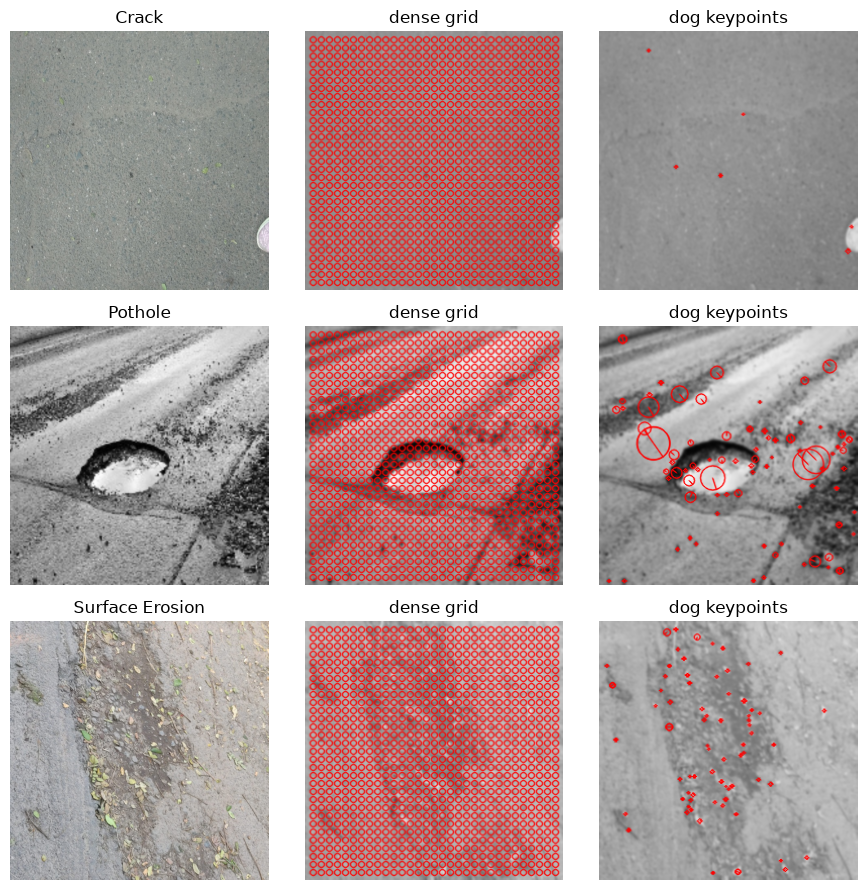

In [12]:
save_keypoint_picture(table)

### visual words (dense sift, fold 0 vocabulary)

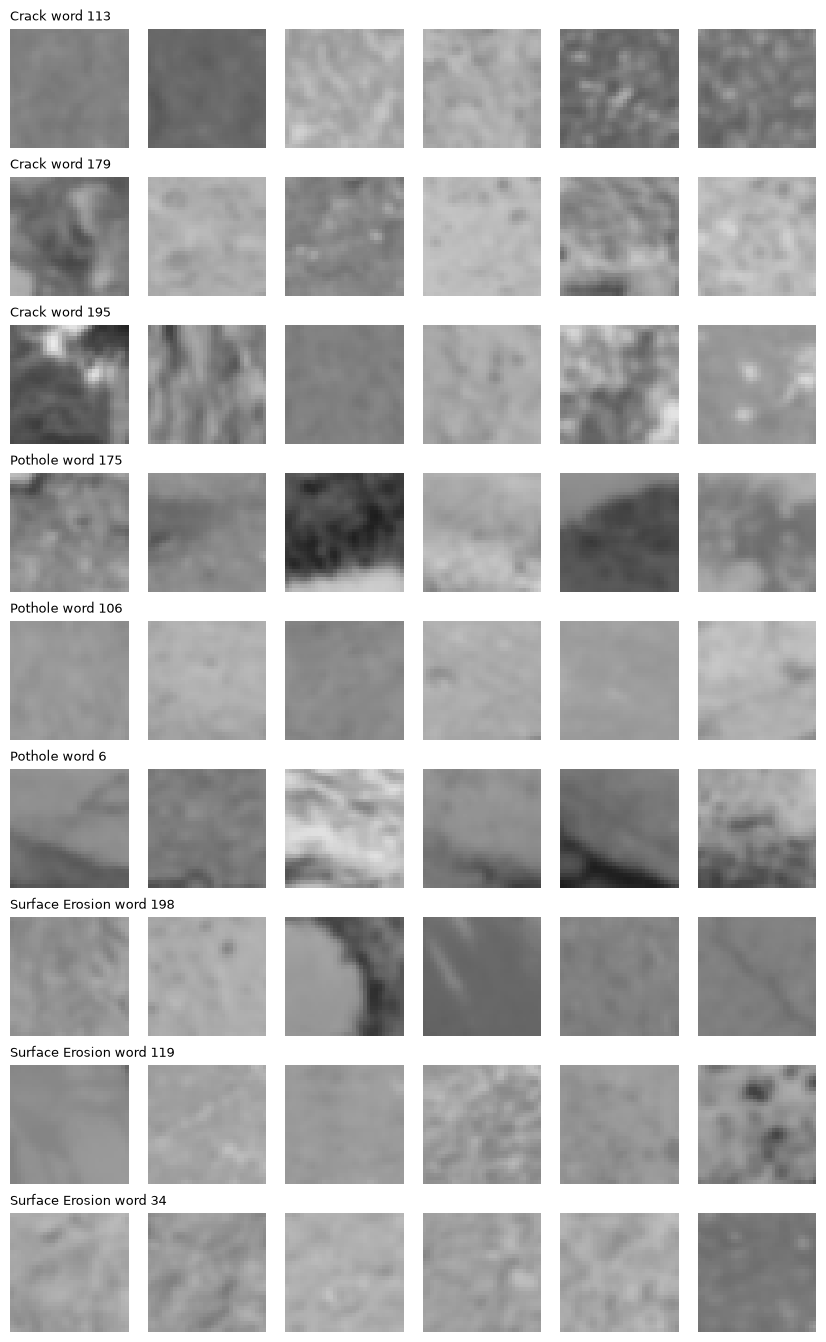

In [13]:
words = words_for_every_fold(table, dense_descs)
typical = class_words(table, words[0])
save_word_patches(table, words[0], dense_xys, typical)

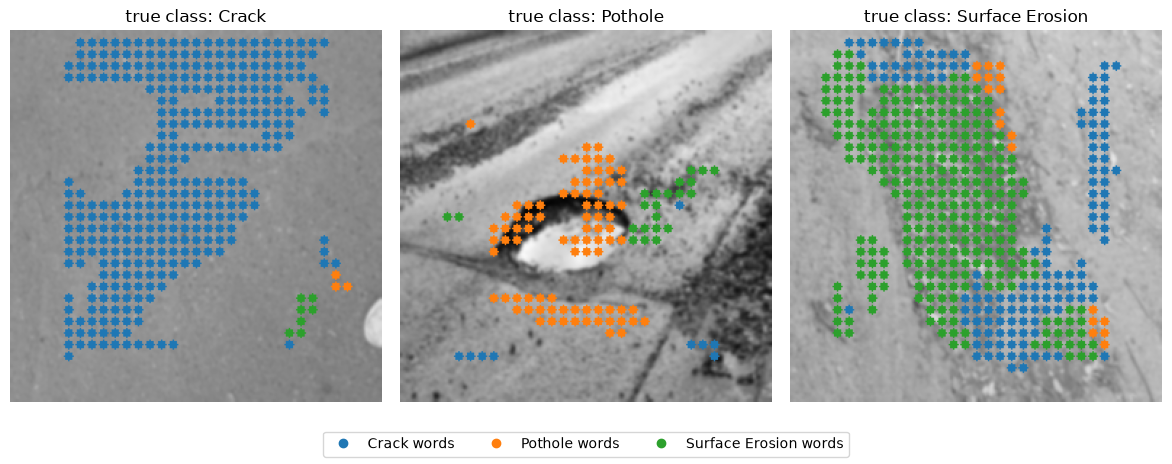

In [14]:
save_word_map(table, words[0], dense_xys)

### main result: dense sift, 200 words, pyramid

linear svm
  fold 0: macro f1 0.717 C 0.01 gamma scale numbers 1000
  fold 1: macro f1 0.678 C 0.01 gamma scale numbers 1000
  fold 2: macro f1 0.679 C 100 gamma scale numbers 1000
  fold 3: macro f1 0.719 C 0.01 gamma scale numbers 1000
  fold 4: macro f1 0.708 C 0.01 gamma scale numbers 1000
  accuracy 0.700 +- 0.019
  macro f1 0.700 +- 0.020
    f1 Crack: 0.775
    f1 Pothole: 0.694
    f1 Surface Erosion: 0.632


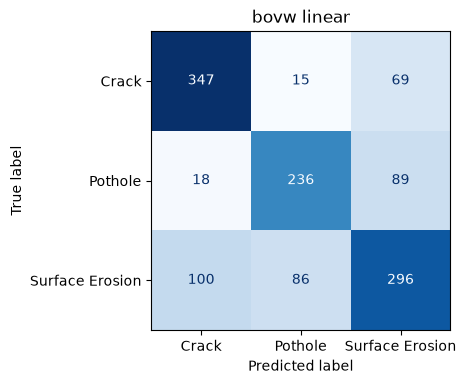

{'numbers used': np.float64(1000.0),
 'accuracy': np.float64(0.6998260924555746),
 'macro f1': np.float64(0.7000258420520163),
 'macro f1 std': np.float64(0.020178500898068247),
 'f1 Crack': np.float64(0.7745535714285714),
 'f1 Pothole': np.float64(0.6941176470588235),
 'f1 Surface Erosion': np.float64(0.6324786324786325)}

In [15]:
xs = feature_matrices(words, dense_xys, pyramid=True)
print("linear svm")
run_svm(table, xs, "linear", title="bovw linear")

rbf svm
  fold 0: macro f1 0.734 C 100 gamma 0.001 numbers 1000
  fold 1: macro f1 0.794 C 1 gamma 0.001 numbers 1000
  fold 2: macro f1 0.732 C 1 gamma 0.001 numbers 1000
  fold 3: macro f1 0.777 C 100 gamma 0.001 numbers 1000
  fold 4: macro f1 0.760 C 10 gamma 0.001 numbers 1000
  accuracy 0.757 +- 0.028
  macro f1 0.760 +- 0.027
    f1 Crack: 0.807
    f1 Pothole: 0.755
    f1 Surface Erosion: 0.717


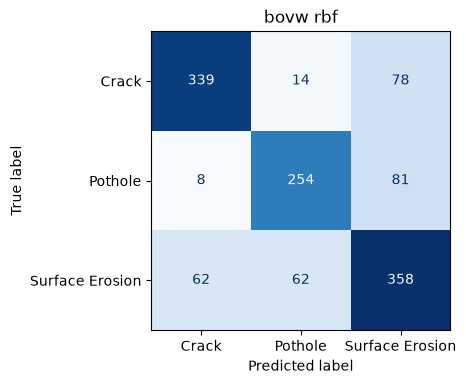

{'numbers used': np.float64(1000.0),
 'accuracy': np.float64(0.7571871245178018),
 'macro f1': np.float64(0.7595134681269807),
 'macro f1 std': np.float64(0.027021032408648827),
 'f1 Crack': np.float64(0.8071428571428572),
 'f1 Pothole': np.float64(0.7548291233283804),
 'f1 Surface Erosion': np.float64(0.7167167167167167)}

In [16]:
print("rbf svm")
run_svm(table, xs, "rbf", title="bovw rbf")

### ablation: vocabulary size and spatial pyramid

In [17]:
rows = []
for size in [50, 200, 500]:
    size_words = words if size == VOCAB_SIZE else words_for_every_fold(table, dense_descs, size)
    for pyramid in [False, True]:
        size_xs = feature_matrices(size_words, dense_xys, size, pyramid)
        for kernel in ["linear", "rbf"]:
            print(f"running {size} words pyramid {pyramid} with {kernel}")
            summary = run_svm(table, size_xs, kernel, show_details=False)
            rows.append({"words": size, "pyramid": pyramid, "svm": kernel, **summary})

vocab_table = pd.DataFrame(rows)
vocab_table.to_csv(OUTPUT_DIR / "vocab_pyramid.csv", index=False)
print()
print(vocab_table.round(3).to_string(index=False))

running 50 words pyramid False with linear
running 50 words pyramid False with rbf
running 50 words pyramid True with linear
running 50 words pyramid True with rbf
running 200 words pyramid False with linear
running 200 words pyramid False with rbf
running 200 words pyramid True with linear
running 200 words pyramid True with rbf
running 500 words pyramid False with linear
running 500 words pyramid False with rbf
running 500 words pyramid True with linear
running 500 words pyramid True with rbf

 words  pyramid    svm  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
    50    False linear          50.0     0.698     0.700         0.036     0.766       0.729               0.604
    50    False    rbf          50.0     0.686     0.687         0.022     0.761       0.701               0.603
    50     True linear         250.0     0.698     0.699         0.024     0.768       0.718               0.612
    50     True    rbf         250.0     0.721 

### ablation: dense grid vs dog keypoints

In [18]:
dog_words = words_for_every_fold(table, dog_descs)
rows = []
for name, w, xys in [("dense", words, dense_xys), ("dog", dog_words, dog_xys)]:
    kp_xs = feature_matrices(w, xys, pyramid=True)
    for kernel in ["linear", "rbf"]:
        print(f"running {name} with {kernel}")
        summary = run_svm(table, kp_xs, kernel, show_details=False)
        rows.append({"keypoints": name, "svm": kernel, **summary})

keypoint_table = pd.DataFrame(rows)
keypoint_table.to_csv(OUTPUT_DIR / "dense_vs_dog.csv", index=False)
print()
print(keypoint_table.round(3).to_string(index=False))

running dense with linear
running dense with rbf
running dog with linear
running dog with rbf

keypoints    svm  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
    dense linear        1000.0     0.700     0.700         0.020     0.775       0.694               0.632
    dense    rbf        1000.0     0.757     0.760         0.027     0.807       0.755               0.717
      dog linear        1000.0     0.657     0.662         0.022     0.692       0.709               0.586
      dog    rbf        1000.0     0.744     0.750         0.018     0.765       0.793               0.693


### ablation: pca

In [19]:
rows = []
for kernel in ["linear", "rbf"]:
    for use_pca in [False, True]:
        print(f"running {kernel} pca {use_pca}")
        summary = run_svm(table, xs, kernel, use_pca=use_pca, show_details=False)
        rows.append({"svm": kernel, "pca": use_pca, **summary})

pca_table = pd.DataFrame(rows)
pca_table.to_csv(OUTPUT_DIR / "pca.csv", index=False)
print()
print(pca_table.round(3).to_string(index=False))

running linear pca False
running linear pca True
running rbf pca False
running rbf pca True

   svm   pca  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
linear False        1000.0     0.700     0.700         0.020     0.775       0.694               0.632
linear  True         390.4     0.722     0.722         0.025     0.795       0.716               0.657
   rbf False        1000.0     0.757     0.760         0.027     0.807       0.755               0.717
   rbf  True         390.4     0.745     0.747         0.025     0.803       0.747               0.692
